In [ ]:
import cv2 # OpenCV library
import os

# 1 Load both images as greyscale (pixels 0–255)
img1_path = "nailong.jpg"
img2_path = "nailong2.jpg"

if not os.path.exists(img1_path) or not os.path.exists(img2_path):
    print(f"错误：找不到图片文件！请确保 '{img1_path}' 和 '{img2_path}' 已上传到当前工作目录。")
else:
    img1 = cv2.imread(img1_path, cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(img2_path, cv2.IMREAD_GRAYSCALE)

    # 2 Create the detector: keep the 500 best keypoints
    orb = cv2.ORB_create(nfeatures=500)

    # 3 Stages 0–2: pyramid, FAST, orientation, rBRIEF
    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        print("未能从图像中提取到足够的特征点描述子。")
    else:
        # 4 Stage 3: compare bit strings by Hamming distance
        bf = cv2.BFMatcher(cv2.NORM_HAMMING)
        pairs = bf.knnMatch(des1, des2, k=2) # 2 nearest each

        # 5 Ratio test: keep a match only if it clearly beats #2
        good = [p[0] for p in pairs
                if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
        out = cv2.drawMatches(img1, kp1, img2, kp2, good, None)
        print(f"Keypoints image 1: {len(kp1)}, Descriptors shape: {des1.shape}, Good matches: {len(good)}")

Keypoints image 1: 117, Descriptors shape: (117, 32), Good matches: 6


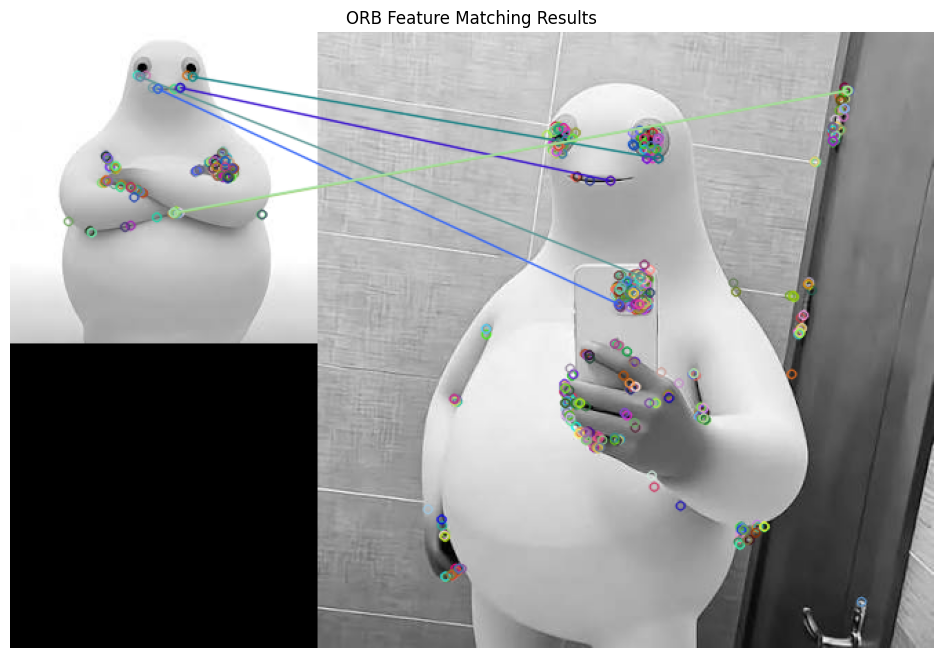

In [ ]:
import matplotlib.pyplot as plt

# Convert BGR (OpenCV format) to RGB (Matplotlib format) for correct color visualization
if 'out' in globals():
    out_rgb = cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(15, 8))
    plt.imshow(out_rgb)
    plt.title("ORB Feature Matching Results")
    plt.axis('off')
    plt.savefig('/content/ORB_Result.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("未检测到匹配结果变量 'out'，请确保上一单元格已成功执行。")

In [ ]:
from google.colab import files

files.download('/content/ORB_Result.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Reflection & Discussion
1.Feature effectiveness
The eye edges, mouth, hand/phone boundaries, and the character's outline provide useful local contrast. ORB can describe these corners and edges, so they are more helpful than the smooth areas of the body.
2.Ambiguous features
Some matches may land on the tiled wall, door edges, or repeated body textures instead of the same part of Nailong. ORB compares local grayscale patterns; it does not understand that two regions depict the same character. The different pose and backgrounds also create mismatches.
3.Robustness challenge
ORB assigns an orientation to keypoints, which helps when an object is rotated moderately. Large viewpoint or pose changes can still reduce matches. It is somewhat robust to small lighting changes, but strong shadows or major brightness changes alter local patterns and may make matching less reliable.